# Lecture 29: Correlation
v.ekc

Prediction, part two (part one was Lecture 10!): to predict one variable from another we first need to *measure* how tightly they're related. Now we can talk about correlation: *r*!

**Today's sections:**
1. Prediction recap — heights
2. Association
3. The correlation coefficient
4. What r doesn't tell you

In [1]:
import matplotlib
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
import numpy as np
plots.style.use('fivethirtyeight')

In [2]:
def r_scatter(r):
    plots.figure(figsize=(5,5))
    "Generate a scatter plot with a correlation approximately r"
    x = np.random.normal(0, 1, 1000)
    z = np.random.normal(0, 1, 1000)
    y = r*x + (np.sqrt(1-r**2))*z
    plots.scatter(x, y, color='darkblue', s=20)
    plots.xlim(-4, 4)
    plots.ylim(-4, 4)

---
## 1. Prediction Recap — Heights

Galton's data and the nearest-neighbor idea from Lecture 10: to predict a child's height, average the children of similar parents.

In [3]:
# Note: Child heights are the **adult** heights of children in a family
families = Table.read_table('family_heights.csv')
families

family,father,mother,child,children,order,sex
1,78.5,67,73.2,4,1,male
1,78.5,67,69.2,4,2,female
1,78.5,67,69,4,3,female
1,78.5,67,69,4,4,female
2,75.5,66.5,73.5,4,1,male
2,75.5,66.5,72.5,4,2,male
2,75.5,66.5,65.5,4,3,female
2,75.5,66.5,65.5,4,4,female
3,75,64,71,2,1,male
3,75,64,68,2,2,female


One number per family: average the two parents:

In [4]:
parent_avgs = (families.column('father') + families.column('mother'))/2

In [5]:
heights = Table().with_columns(
    'Parent Average', parent_avgs,
    'Child', families.column('child'),
)
heights

Parent Average,Child
72.75,73.2
72.75,69.2
72.75,69
72.75,69
71,73.5
71,72.5
71,65.5
71,65.5
69.5,71
69.5,68


Every dot is one family, child height against parent average:

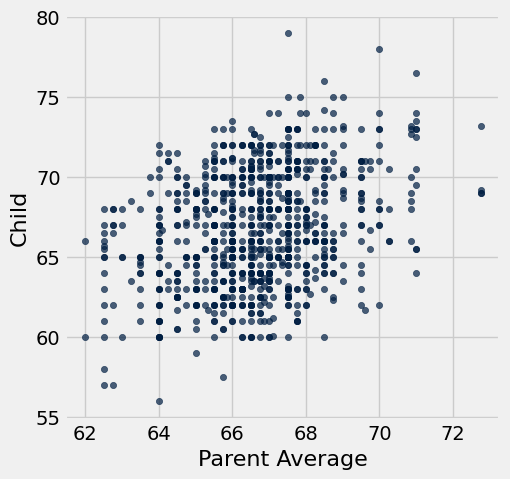

In [6]:
heights.scatter('Parent Average', 'Child')

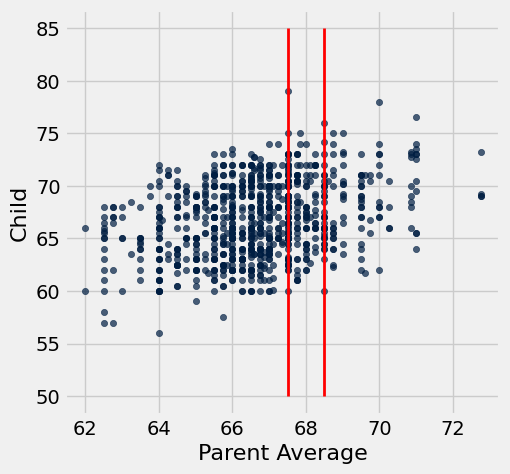

In [7]:
heights.scatter('Parent Average', 'Child')
plots.plot([67.5, 67.5], [50, 85], color='red', lw=2)
plots.plot([68.5, 68.5], [50, 85], color='red', lw=2);

Average the children inside that strip: one prediction for 68-inch parents:

In [8]:
nearby = heights.where('Parent Average', are.between(67.5, 68.5))
nearby_mean = np.average(nearby.column('Child'))
nearby_mean

67.620000000000005

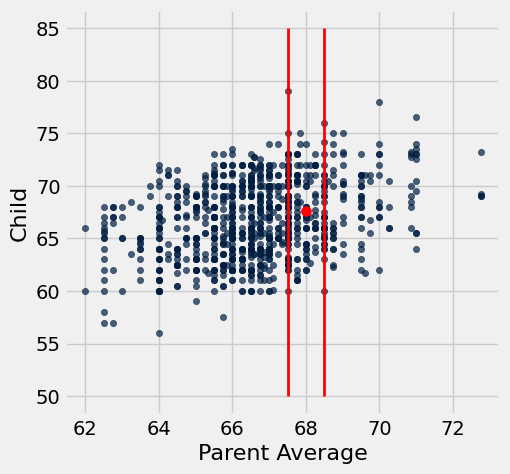

In [9]:
heights.scatter('Parent Average', 'Child')
plots.plot([67.5, 67.5], [50, 85], color='red', lw=2)
plots.plot([68.5, 68.5], [50, 85], color='red', lw=2)
plots.scatter(68, nearby_mean, color='red', s=50);

Wrap the idea in a function and predict for every parent average:

In [10]:
def predict_child(h):
    """Predict the height of a child whose parents have a parent average height of p_avg.
    
    The prediction is the average height of the children whose parent average height is
    in the range p_avg plus or minus 0.5.
    """
    nearby = heights.where('Parent Average', are.between(h - 1/2, h + 1/2))
    return np.average(nearby.column('Child'))

In [67]:
heights_with_predictions = heights.with_columns(
    'Prediction', heights.apply(predict_child, 'Parent Average'))

heights_with_predictions.show(3)

Parent Average,Child,Prediction
72.75,73.2,70.1
72.75,69.2,70.1
72.75,69,70.1


The predictions trace the graph of averages through the cloud:

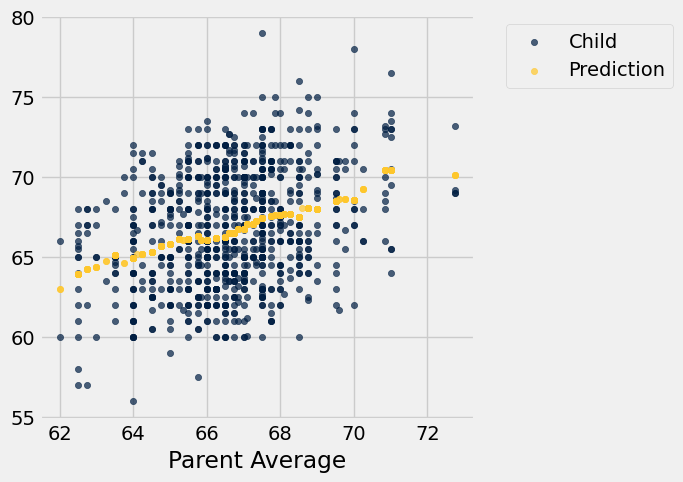

In [12]:
heights_with_predictions.scatter('Parent Average')

### Try It 1: Predict a height

1. Use `predict_child` to predict the height of a child whose parent average is **64 inches**. And for **70 inches**?

2. The prediction for 70-inch parents is about 68.6 inches, shorter than the parents. Look at the scatter: why might that happen?

In [13]:
# 1. predict_child at 64 and at 70


*2. Your interpretation: (double-click to edit)*

<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*The function does the strip-and-average for you.*

```python
# 1.
predict_child(64), predict_child(70)     # about 64.9 and 68.6
```

*2. Children of unusually tall parents tend to be tall, but less extreme than their parents: the cloud pulls predictions toward the average*

</details>

---
## 2. Association

Hybrid cars: which variables move together? It is always helpful to visualze a new dataset!

In [14]:
hybrid = Table.read_table('hybrid.csv')
hybrid

vehicle,year,msrp,acceleration,mpg,class
Prius (1st Gen),1997,24509.7,7.46,41.26,Compact
Tino,2000,35355,8.2,54.1,Compact
Prius (2nd Gen),2000,26832.2,7.97,45.23,Compact
Insight,2000,18936.4,9.52,53,Two Seater
Civic (1st Gen),2001,25833.4,7.04,47.04,Compact
Insight,2001,19036.7,9.52,53,Two Seater
Insight,2002,19137,9.71,53,Two Seater
Alphard,2003,38084.8,8.33,40.46,Minivan
Insight,2003,19137,9.52,53,Two Seater
Civic,2003,14071.9,8.62,41,Compact


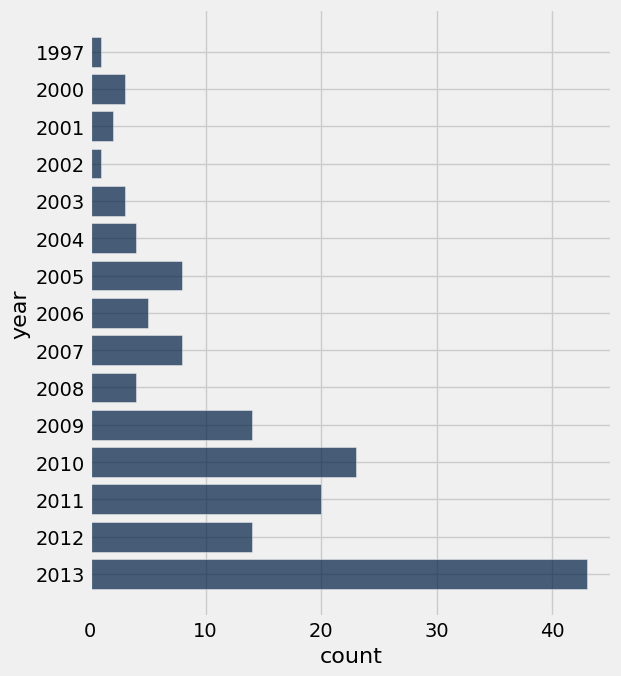

In [66]:
hybrid.group('year').barh('year')

In [15]:
hybrid.sort('msrp', descending=True)

vehicle,year,msrp,acceleration,mpg,class
Lexus LS600h/hL,2007,118544,17.54,21,Midsize
ActiveHybrid 7,2010,104300,20.41,22.11,Large
ActiveHybrid 7i,2011,102606,18.18,20,Midsize
ActiveHybrid X6,2009,97237.9,17.96,18.82,SUV
S400 Long,2009,96208.9,13.89,26.34,Large
Panamera S,2013,96150,18.52,25,Large
Panamera S,2012,95283.9,17.54,25,Large
S400,2013,92350,13.89,21,Large
S400,2010,88212.8,12.99,21,Large
ActiveHybrid 7L,2013,84300,18.18,25,Large


Now a scatter: price against mpg:

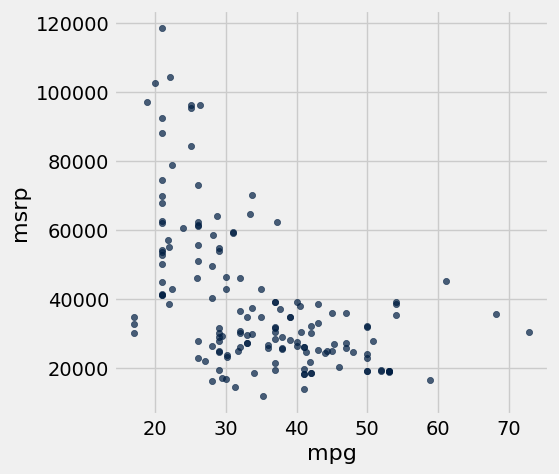

In [16]:
hybrid.scatter('mpg', 'msrp')

To check the pattern within one class of car, filter to the SUVs:

In [17]:
suv = hybrid.where('class', 'SUV')
suv.num_rows

39

Price against acceleration and against mpg, SUVs only:

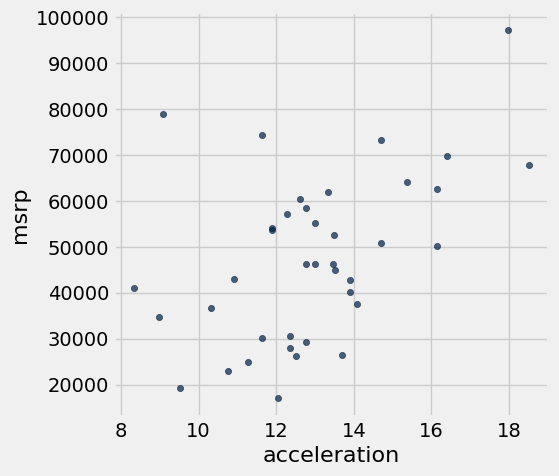

In [18]:
suv.scatter('acceleration', 'msrp')

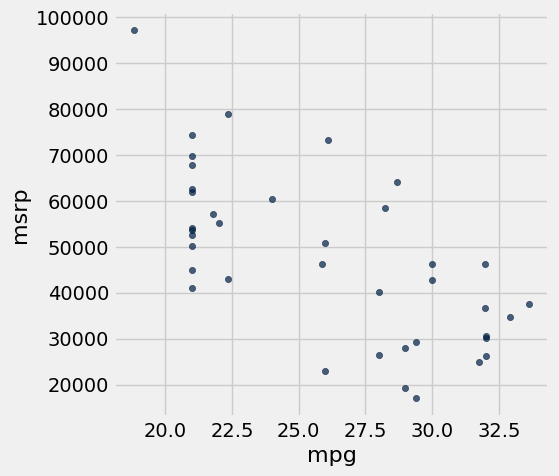

In [19]:
suv.scatter('mpg', 'msrp')

Standard units make the association *comparable*, same picture, universal ruler:

In [20]:
def standard_units(x):
    "Convert any array of numbers to standard units."
    return (x - np.average(x)) / np.std(x)

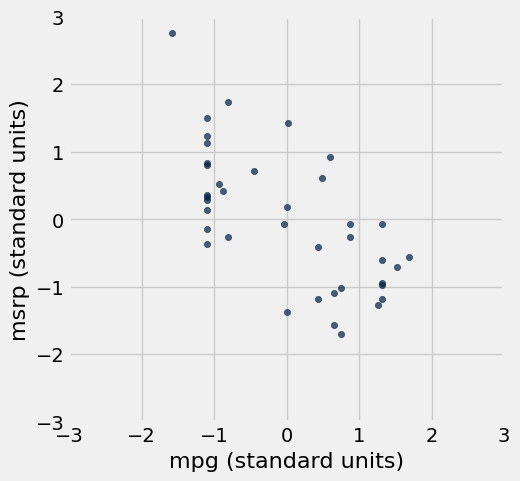

In [21]:
Table().with_columns(
    'mpg (standard units)',  standard_units(suv.column('mpg')), 
    'msrp (standard units)', standard_units(suv.column('msrp'))
).scatter(0, 1)
plots.xlim(-3, 3)
plots.ylim(-3, 3);

Same treatment for acceleration: original units first, then standard units:

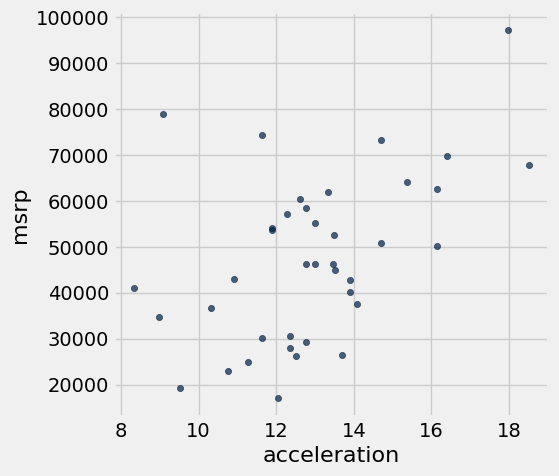

In [22]:
suv.scatter('acceleration', 'msrp')

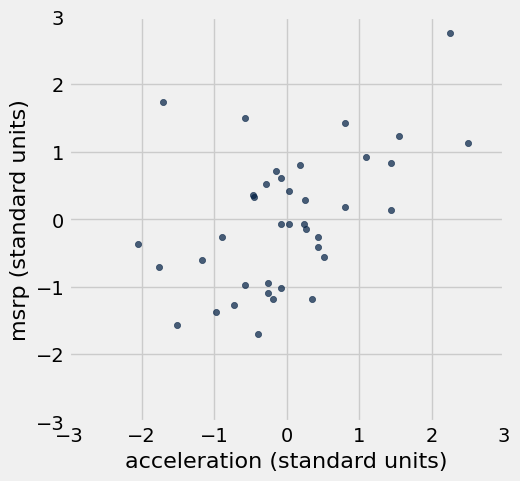

In [23]:
Table().with_columns(
    'acceleration (standard units)', standard_units(suv.column('acceleration')), 
    'msrp (standard units)',         standard_units(suv.column('msrp'))
).scatter(0, 1)
plots.xlim(-3, 3)
plots.ylim(-3, 3);

### Try It 2: The whole fleet 😊

1. Make the scatter of `acceleration` vs. `msrp` for **all** hybrid cars, not just SUVs.

2. Does the association look stronger or weaker than the SUV-only version above?

3. Your choice: pick any other pair of numerical columns in `hybrid` and scatter them.

In [24]:
# 1. all cars: acceleration vs msrp


*2. Your interpretation: (double-click to edit)*

In [25]:
# 3. your choice


<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*Same call on the bigger table; with every class of car included, the upward trend is tighter.*

```python
# 1.
hybrid.scatter('acceleration', 'msrp')

# 3. one of many right answers
hybrid.scatter('acceleration', 'mpg')
```

*2. Stronger: restricting to one class of car narrows the range of acceleration, which weakens the visible trend.*

</details>

---
## 3. The Correlation Coefficient r

**r = the average of the products of standard units.** It measures *linear* association: how consistently do the two variables sit on the same side of their means?

### 📋 Reference Table

| Fact about r | |
|---|---|
| range | always between −1 and 1 |
| r = ±1 | points exactly on a line |
| r = 0 | no *linear* association |
| units | none — it's based on standard units |
| symmetric | r(x, y) = r(y, x) |
| formula | `np.average(su(x) * su(y))` |

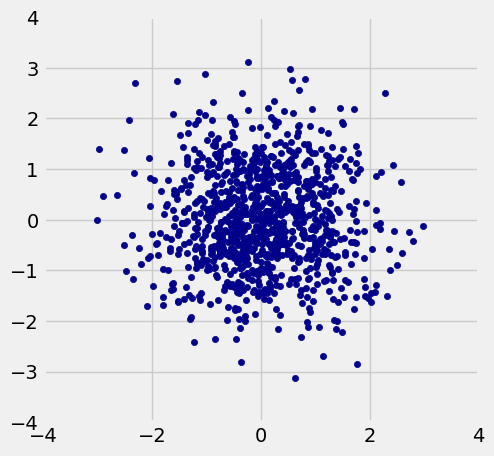

In [26]:
r_scatter(0)

Now compute r by hand on six little points:

In [27]:
x = np.arange(1, 7, 1)
y = make_array(2, 3, 1, 5, 2, 7)
t = Table().with_columns(
        'x', x,
        'y', y
    )
t

x,y
1,2
2,3
3,1
4,5
5,2
6,7


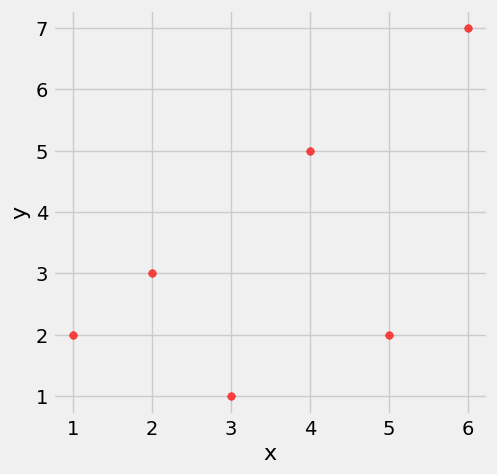

In [28]:
t.scatter('x', 'y', s=30, color='red')

Step 1: put both columns in standard units:

In [29]:
t = t.with_columns(
        'x (standard units)', standard_units(x),
        'y (standard units)', standard_units(y)
    )
t

x,y,x (standard units),y (standard units)
1,2,-1.46385,-0.648886
2,3,-0.87831,-0.162221
3,1,-0.29277,-1.13555
4,5,0.29277,0.811107
5,2,0.87831,-0.648886
6,7,1.46385,1.78444


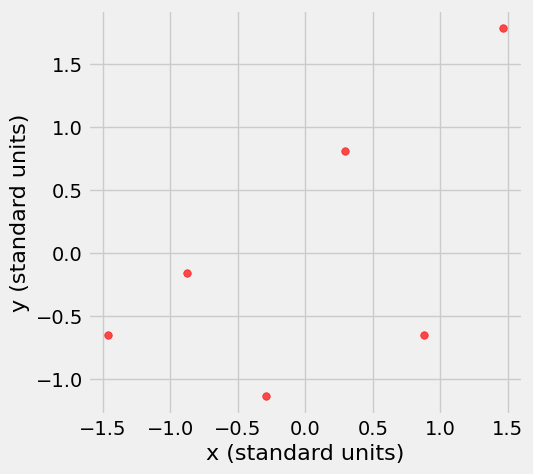

In [30]:
t.scatter(2, 3, s=30, color='red')

Steps 2 and 3: multiply pair by pair, then average the products:

In [31]:
t = t.with_columns(
    'product of standard units', t.column(2) * t.column(3))
t

x,y,x (standard units),y (standard units),product of standard units
1,2,-1.46385,-0.648886,0.949871
2,3,-0.87831,-0.162221,0.142481
3,1,-0.29277,-1.13555,0.332455
4,5,0.29277,0.811107,0.237468
5,2,0.87831,-0.648886,-0.569923
6,7,1.46385,1.78444,2.61215


In [32]:
# r is the average of the products of the standard units

r = np.average(t.column(2) * t.column(3))
r

0.61741639718977093

Package the three steps into a function we can reuse all week:

In [33]:
def correlation(t, x, y):
    """t is a table; x and y are column labels"""
    x_in_standard_units = standard_units(t.column(x))
    y_in_standard_units = standard_units(t.column(y))
    return np.average(x_in_standard_units * y_in_standard_units)

In [34]:
correlation(t, 'x', 'y')

0.61741639718977093

### Switching Axes

In [35]:
correlation(t, 'x', 'y')

0.61741639718977093

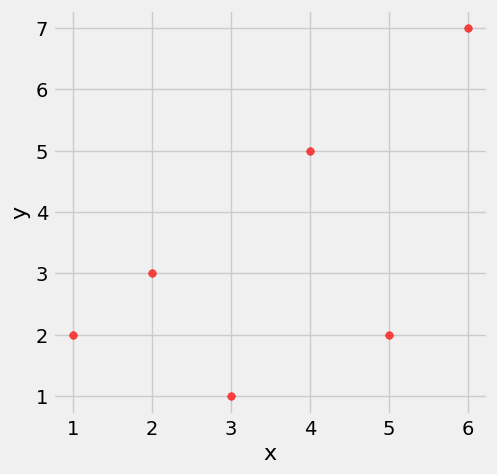

In [36]:
t.scatter('x', 'y', s=30, color='red')

Flip the axes and look again:

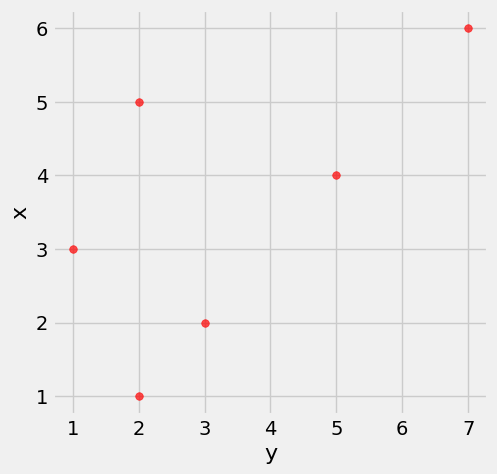

In [37]:
t.scatter('y', 'x', s=30, color='red')

In [38]:
correlation(t, 'y', 'x')

0.61741639718977093

Back to the real cars: eyeball each scatter, then let r settle it:

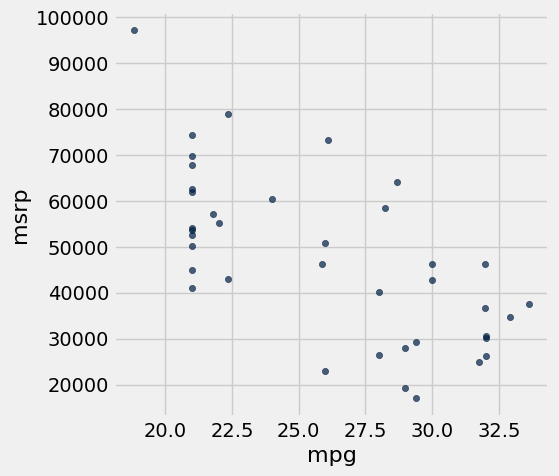

In [39]:
suv.scatter('mpg', 'msrp')

In [40]:
correlation(suv, 'mpg', 'msrp')

-0.6667143635709919

And the acceleration pair:

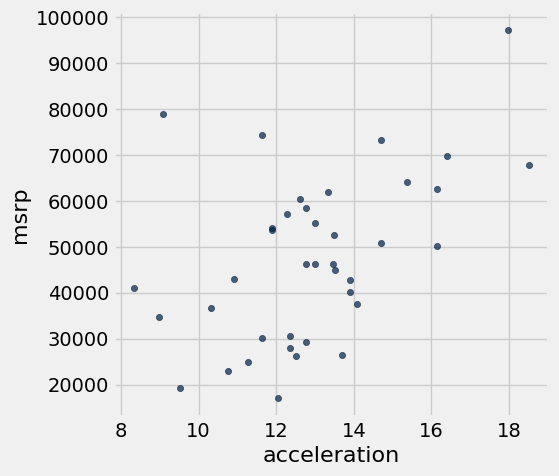

In [41]:
suv.scatter('acceleration', 'msrp')

In [42]:
correlation(suv, 'acceleration', 'msrp')

0.48699799279959155

### Try It 3: Guess the r 😊

1. Before you run it: picture what r = 0.9 should look like. Now run `r_scatter(0.9)`. Close?

2. Try it again with r = −0.5.

3. Your choice: find the r value where the cloud stops looking like a trend to you.

In [43]:
# 1. r_scatter(0.9)


In [44]:
# 2. r_scatter(-0.5)


In [45]:
# 3. your threshold


<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*There are no wrong guesses :) Most people stop seeing a trend somewhere around r = 0.2 or 0.3.*

```python
# 1.
r_scatter(0.9)

# 2.
r_scatter(-0.5)

# 3. one of many right answers
r_scatter(0.25)
```

</details>

---
## 4. What r Doesn't Tell You ⚠️

Three ways r can mislead: nonlinearity, outliers, and aggregated data:

### Nonlinearity

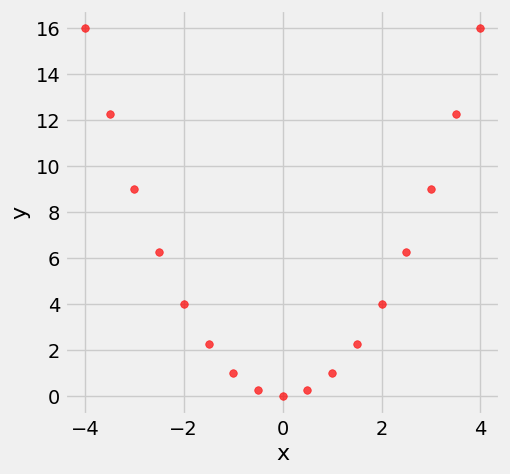

In [46]:
new_x = np.arange(-4, 4.1, 0.5)
nonlinear = Table().with_columns(
        'x', new_x,
        'y', new_x**2
    )
nonlinear.scatter('x', 'y', s=30, color='r')

In [47]:
correlation(nonlinear, 'x', 'y')

0.0

> **r = 0 does NOT mean "no relationship"**, this parabola has a perfect relationship and zero *linear* correlation.

### Try It 4: Eyeball, then compute 😊

1. Guess r for `hybrid` (all cars, not just SUVs): `mpg` vs. `msrp`. Its scatter is in Section 2. Then compute it.

2. Without computing: is r for `msrp` vs. `mpg` (axes switched) different? Check.

In [48]:
# 1. correlation(hybrid, 'mpg', 'msrp')


In [49]:
# 2. axes switched


<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*About −0.53: negative (higher mpg, cheaper car) and weaker than the SUV-only −0.67. And switching axes changes nothing: r is symmetric.*

*The all-cars scatter in Section 2 is curved, yet r is far from 0. A sizable r does not mean that a straight line is the best description of the relation: look at the scatter.*

```python
# 1.
correlation(hybrid, 'mpg', 'msrp')      # ≈ -0.53

# 2.
correlation(hybrid, 'msrp', 'mpg')      # identical
```

</details>

### Outliers

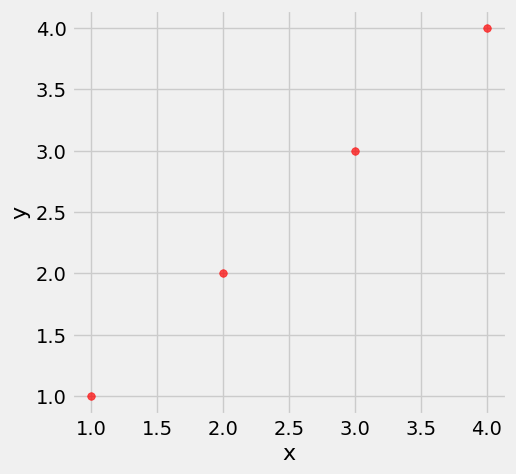

In [50]:
line = Table().with_columns(
        'x', make_array(1, 2, 3, 4),
        'y', make_array(1, 2, 3, 4)
    )
line.scatter('x', 'y', s=30, color='r')

In [51]:
correlation(line, 'x', 'y')

1.0

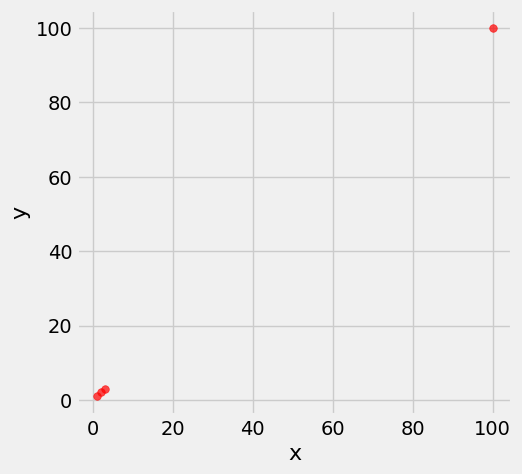

In [52]:
# A point far from the others, but still on the line
line = Table().with_columns(
        'x', make_array(1, 2, 3, 100),
        'y', make_array(1, 2, 3, 100)
    )
line.scatter('x', 'y', s=30, color='r')

In [53]:
correlation(line, 'x', 'y')

1.0

Now four points on a line and one point off it:

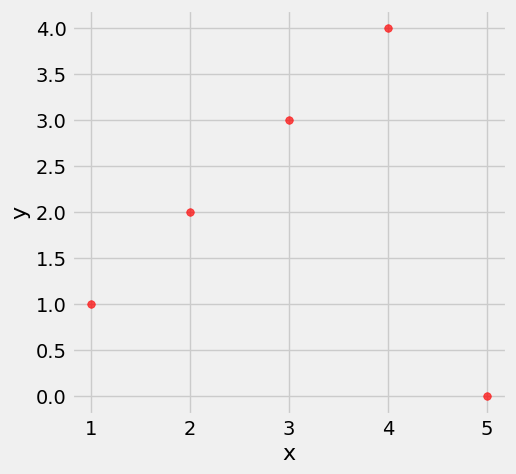

In [54]:
outlier = Table().with_columns(
        'x', make_array(1, 2, 3, 4, 5),
        'y', make_array(1, 2, 3, 4, 0)
    )
outlier.scatter('x', 'y', s=30, color='r')

In [55]:
correlation(outlier, 'x', 'y')

0.0

> **One outlier can wreck r.** Four perfectly-lined-up points plus one stray, and r collapses from 1 to 0. Always look at the scatter, never just the number.

### Ecological Correlations

In [56]:
sat2014 = Table.read_table('sat2014.csv').sort('State')
sat2014

State,Participation Rate,Critical Reading,Math,Writing,Combined
Alabama,6.7,547,538,532,1617
Alaska,54.2,507,503,475,1485
Arizona,36.4,522,525,500,1547
Arkansas,4.2,573,571,554,1698
California,60.3,498,510,496,1504
Colorado,14.3,582,586,567,1735
Connecticut,88.4,507,510,508,1525
Delaware,100,456,459,444,1359
District of Columbia,100,440,438,431,1309
Florida,72.2,491,485,472,1448


One dot per state, not per student:

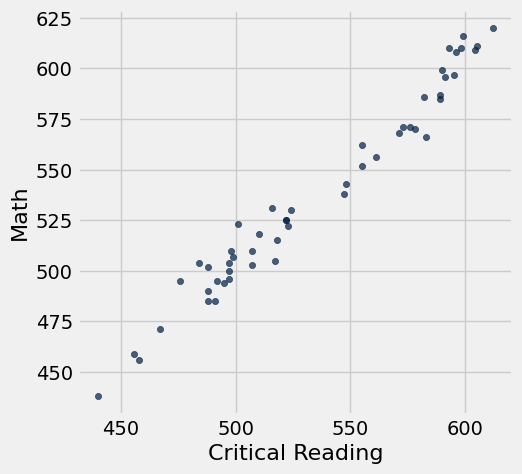

In [57]:
sat2014.scatter('Critical Reading', 'Math')

In [58]:
correlation(sat2014, 'Critical Reading', 'Math')

0.98475584110674341

> **Ecological correlations run high.** Each dot here is a whole *state*: averaging smooths away individual variation, inflating r. A student-level scatter would be much cloudier.

New wrinkle: code each state by how many of its students take the SAT:

In [59]:
def rate_code(x):
    if x <= 25:
        return 'low'
    elif x <= 75:
        return 'medium'
    else:
        return 'high'

In [60]:
rate_codes = sat2014.apply(rate_code, 'Participation Rate')

Attach the codes and peek:

In [61]:
sat2014 = sat2014.with_columns('Rate Code', rate_codes)
sat2014

State,Participation Rate,Critical Reading,Math,Writing,Combined,Rate Code
Alabama,6.7,547,538,532,1617,low
Alaska,54.2,507,503,475,1485,medium
Arizona,36.4,522,525,500,1547,medium
Arkansas,4.2,573,571,554,1698,low
California,60.3,498,510,496,1504,medium
Colorado,14.3,582,586,567,1735,low
Connecticut,88.4,507,510,508,1525,high
Delaware,100,456,459,444,1359,high
District of Columbia,100,440,438,431,1309,high
Florida,72.2,491,485,472,1448,medium


Color the scatter by participation group:

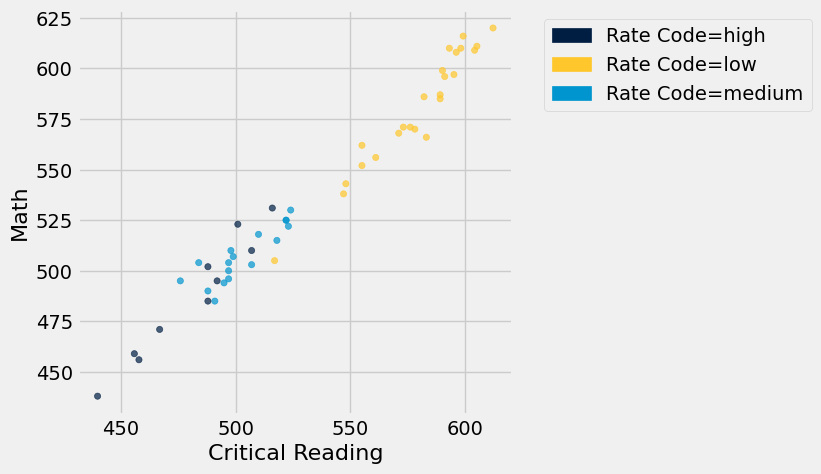

In [62]:
sat2014.scatter('Critical Reading', 'Math', group='Rate Code')

In [63]:
sat2014.where('Rate Code', 'low').show()

State,Participation Rate,Critical Reading,Math,Writing,Combined,Rate Code
Alabama,6.7,547,538,532,1617,low
Arkansas,4.2,573,571,554,1698,low
Colorado,14.3,582,586,567,1735,low
Illinois,4.6,599,616,587,1802,low
Iowa,3.1,605,611,578,1794,low
Kansas,5.3,591,596,566,1753,low
Kentucky,4.6,589,585,572,1746,low
Louisiana,4.6,561,556,550,1667,low
Michigan,3.8,593,610,581,1784,low
Minnesota,5.9,598,610,578,1786,low


> **Simpson's-flavored warning:** grouping states by participation rate changes the story, the strong overall r partly reflects *which states* take the SAT. Aggregated data hides structure.

### Try It 5: Why so high? 😊

1. Compute the correlation between `Participation Rate` and `Combined` score.

2. It comes out strongly *negative*. What story explains that? (Hint: who takes the SAT in a state where almost nobody takes it?)

In [64]:
# 1. r between Participation Rate and Combined


*2. Your interpretation: (double-click to edit)*

<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*One line with `correlation` from Section 3.*

```python
# 1.
correlation(sat2014, 'Participation Rate', 'Combined')     # about -0.91
```

*2. In low-participation states, mostly strong college-bound students opt in, which inflates the state average. Selection, not schooling, drives much of the pattern.*

</details>

---
> **Today's takeaway:** r measures linear association on a universal scale, but it's blind to curves, fragile to outliers, and inflated by aggregation. Look at the scatter. Next: turning r into a prediction *line*.

## Appendix — Quick Reference

Full `datascience` docs: [data8.org/datascience](https://data8.org/datascience/)

### Minimal template — correlation
```python
def standard_units(x):
    return (x - np.average(x)) / np.std(x)

def correlation(t, x, y):
    return np.average(standard_units(t.column(x)) * standard_units(t.column(y)))
```